In [4]:
import pandas as pd
from pathlib import Path

# Locate the dataset
DATA_PATH = Path(r"D:\MarketingIQ\data\bank-full.csv")

# Load the semicolon-separated CSV
df = pd.read_csv(DATA_PATH, sep=";")

# Basic inspection
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True) * 100)

Dataset shape: (45211, 17)

First five rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [5]:
# Check actual missing values
print("Missing values per column:")
print(df.isnull().sum())

# Count unknown values in categorical columns
print("\nUnknown values per column:")

for col in df.select_dtypes(include="object").columns:
    count = (df[col] == "unknown").sum()

    if count > 0:
        print(f"{col}: {count}")

Missing values per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Unknown values per column:
job: 288
education: 1857
contact: 13020
poutcome: 36959


y
no     39922
yes     5289
Name: count, dtype: int64

Percentage distribution:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


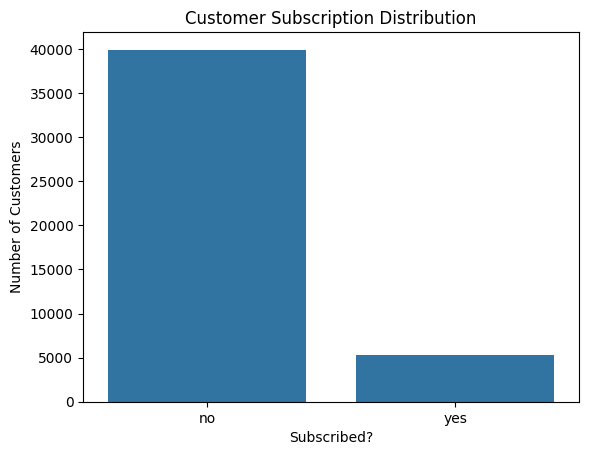

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count each outcome
print(df["y"].value_counts())

# Calculate percentages
print("\nPercentage distribution:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

# Visualize
sns.countplot(data=df, x="y")
plt.title("Customer Subscription Distribution")
plt.xlabel("Subscribed?")
plt.ylabel("Number of Customers")
plt.show()

,age,balance,day,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,63.000000,871.000000,275.000000


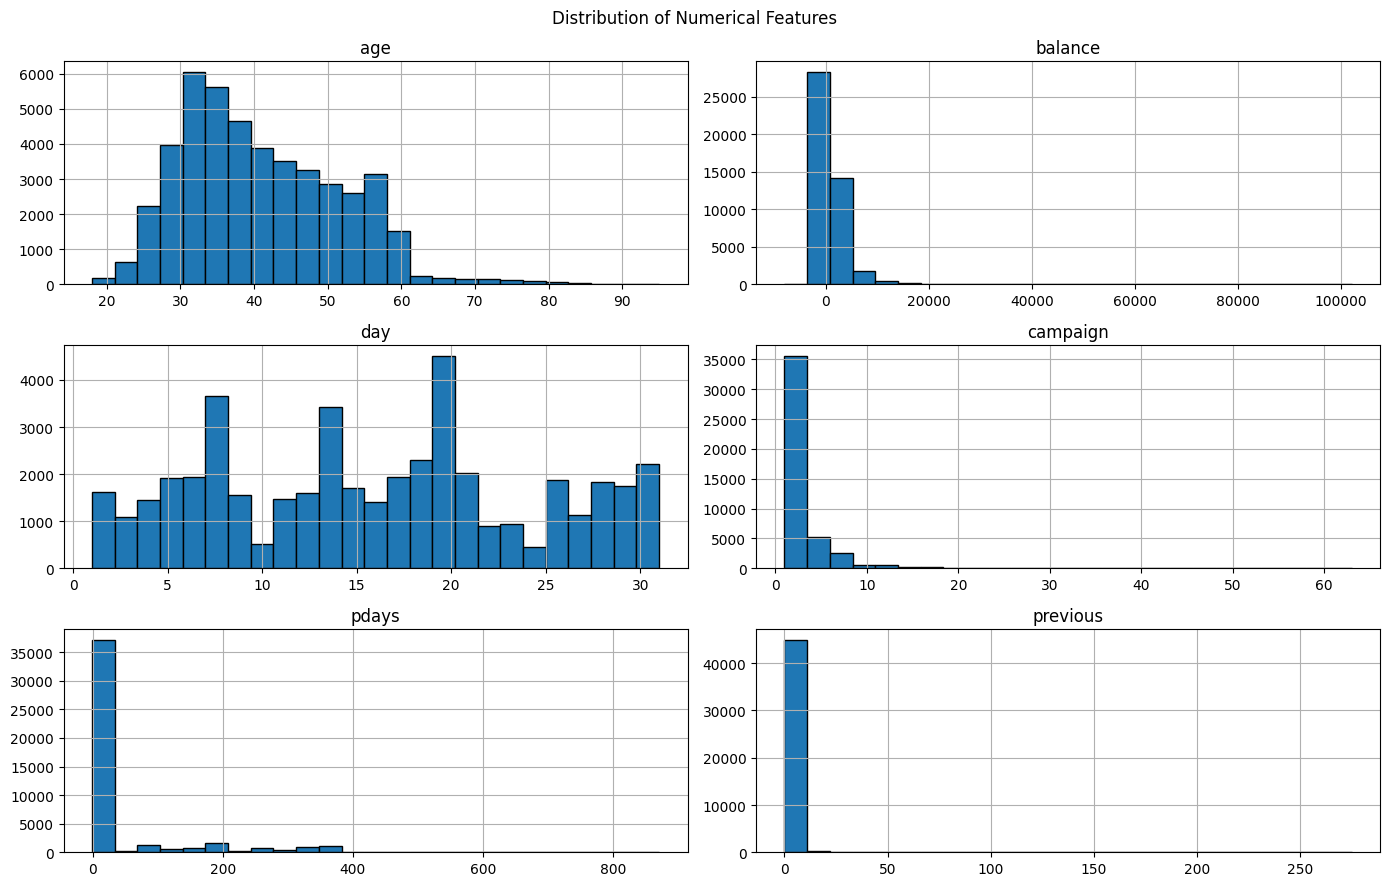

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
numerical_cols = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous"
]

display(df[numerical_cols].describe())

df[numerical_cols].hist(
    figsize=(14, 9),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

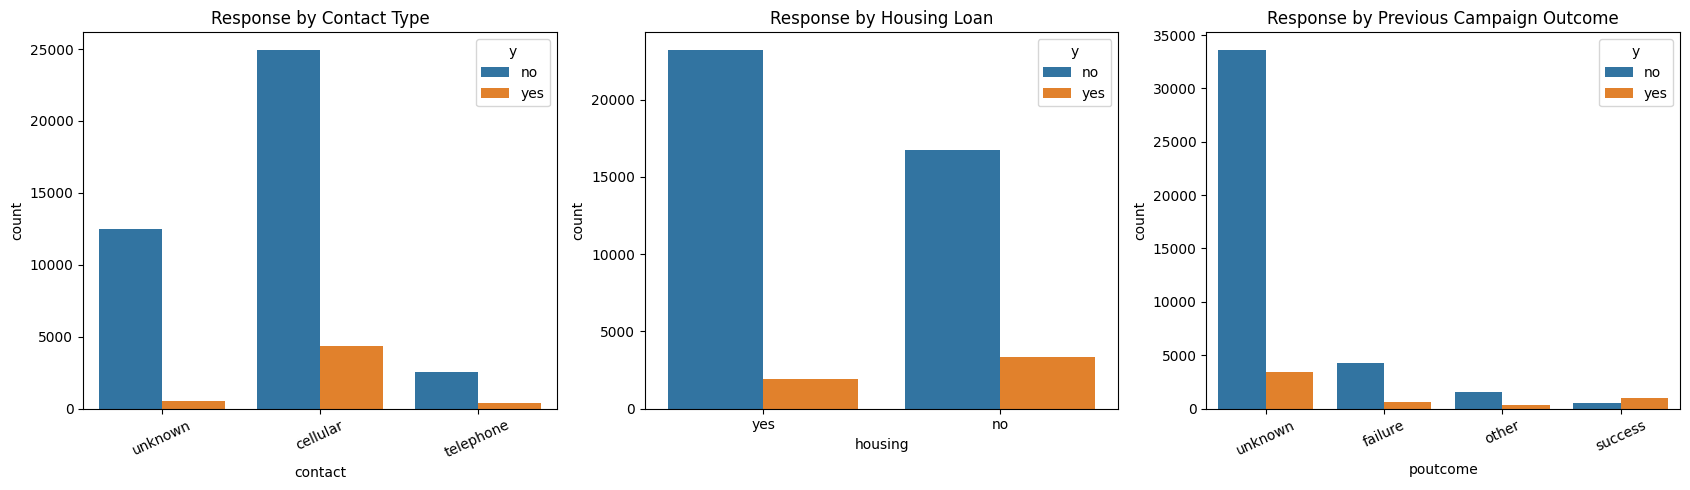

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.countplot(data=df, x="contact", hue="y", ax=axes[0])
axes[0].set_title("Response by Contact Type")
axes[0].tick_params(axis="x", rotation=25)

sns.countplot(data=df, x="housing", hue="y", ax=axes[1])
axes[1].set_title("Response by Housing Loan")

sns.countplot(data=df, x="poutcome", hue="y", ax=axes[2])
axes[2].set_title("Response by Previous Campaign Outcome")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

In [11]:
# Separate input features and target

X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

print("\nInput features:")
print(X.columns.tolist())

Feature matrix shape: (45211, 15)
Target shape: (45211,)

Target values:
y
0    39922
1     5289
Name: count, dtype: int64

Input features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (36168, 15)
Testing features: (9043, 15)

Training target distribution:
y
0    0.883
1    0.117
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.883
1    0.117
Name: proportion, dtype: float64


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify feature types using the training data
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

# Define preprocessing for each feature type
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("\nPreprocessing pipeline created successfully!")

Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Preprocessing pipeline created successfully!


In [14]:
print("===== MarketingIQ Data Preparation =====")

print("Total records:", len(df))
print("Input features:", X.shape[1])
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nMissing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

print("\nTarget contains only 0 and 1:",
      set(y.unique()) == {0, 1})

print("\nDuration excluded:", "duration" not in X.columns)

print("\nAll checks completed.")

===== MarketingIQ Data Preparation =====
Total records: 45211
Input features: 15
Training records: 36168
Testing records: 9043

Missing values in X_train: 0
Missing values in X_test: 0

Target contains only 0 and 1: True

Duration excluded: True

All checks completed.


In [15]:
#step-4
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Build the complete ML pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("MarketingIQ Logistic Regression pipeline created!")

MarketingIQ Logistic Regression pipeline created!


In [16]:
# Train using only the training data
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [17]:
# Predict customer responses
y_pred = model.predict(X_test)

# Predict probability of a positive response
y_proba = model.predict_proba(X_test)[:, 1]

print("First 10 actual outcomes:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted outcomes:")
print(y_pred[:10].tolist())

print("\nFirst 10 predicted response probabilities:")
print(y_proba[:10].round(3).tolist())

First 10 actual outcomes:
[0, 0, 0, 0, 0, 0, 0, 1, 0, 0]

First 10 predicted outcomes:
[0, 0, 0, 0, 1, 0, 0, 1, 0, 0]

First 10 predicted response probabilities:
[0.107, 0.164, 0.212, 0.13, 0.535, 0.288, 0.374, 0.972, 0.456, 0.434]


===== MarketingIQ: Logistic Regression =====
Accuracy:  0.7548
Precision: 0.2662
Recall:    0.6238
F1-score:  0.3732
ROC-AUC:   0.7722

Classification Report:
                 precision    recall  f1-score   support

No subscription       0.94      0.77      0.85      7985
   Subscription       0.27      0.62      0.37      1058

       accuracy                           0.75      9043
      macro avg       0.60      0.70      0.61      9043
   weighted avg       0.86      0.75      0.79      9043



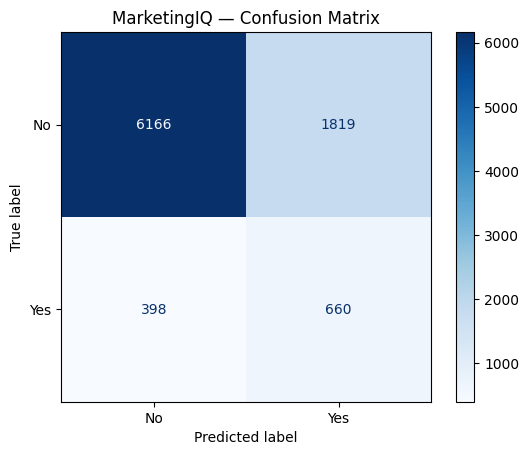

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("===== MarketingIQ: Logistic Regression =====")

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No subscription", "Subscription"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
).plot(cmap="Blues")

plt.title("MarketingIQ — Confusion Matrix")
plt.show()

In [ ]:
#RANDOM FOREST

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("===== MarketingIQ: Random Forest =====")
print(f"Accuracy:  {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision: {precision_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, rf_proba):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["No subscription", "Subscription"],
    zero_division=0
))

===== MarketingIQ: Random Forest =====
Accuracy:  0.8669
Precision: 0.4429
Recall:    0.5350
F1-score:  0.4846
ROC-AUC:   0.8032

Classification Report:
                 precision    recall  f1-score   support

No subscription       0.94      0.91      0.92      7985
   Subscription       0.44      0.53      0.48      1058

       accuracy                           0.87      9043
      macro avg       0.69      0.72      0.70      9043
   weighted avg       0.88      0.87      0.87      9043



In [21]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_proba),
        roc_auc_score(y_test, rf_proba)
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7548,0.2662,0.6238,0.3732,0.7722
1,Random Forest,0.8669,0.4429,0.5350,0.4846,0.8032


In [ ]:
!conda install -c conda-forge xgboost -y

In [1]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
  
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

ModuleNotFoundError: No module named 'xgboost'